## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Anh Bach

**Date:** 10/12/2026

In [1]:
# Your Phase 1 solution to the problem goes here.

#Q1-1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

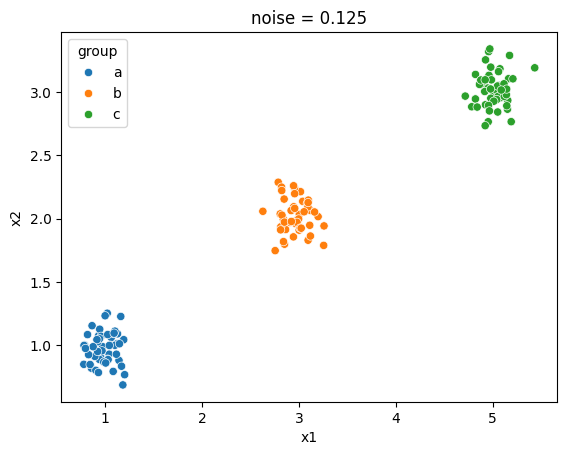

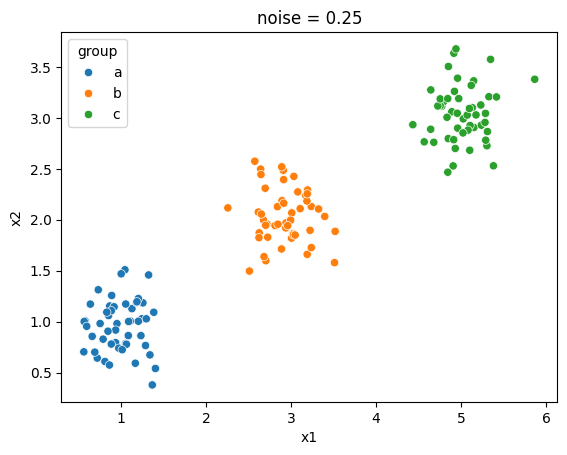

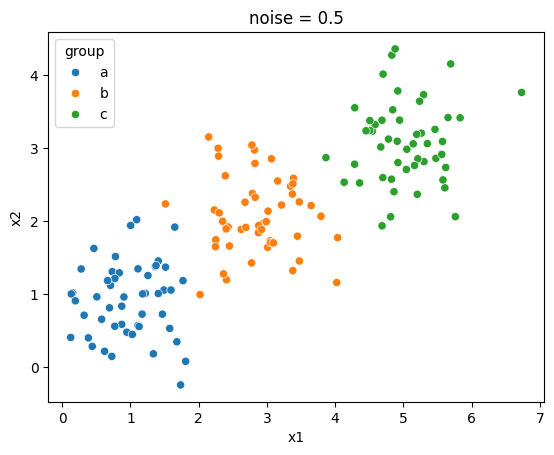

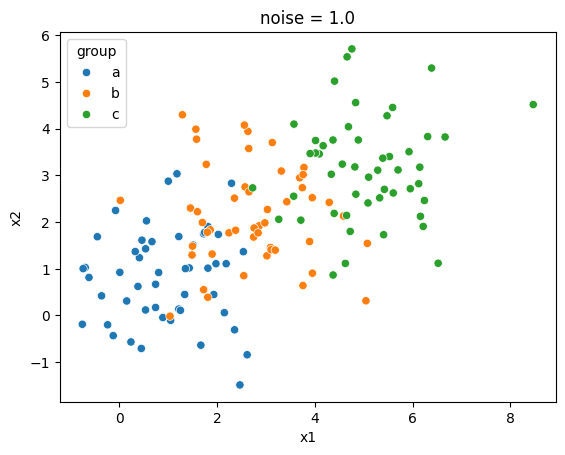

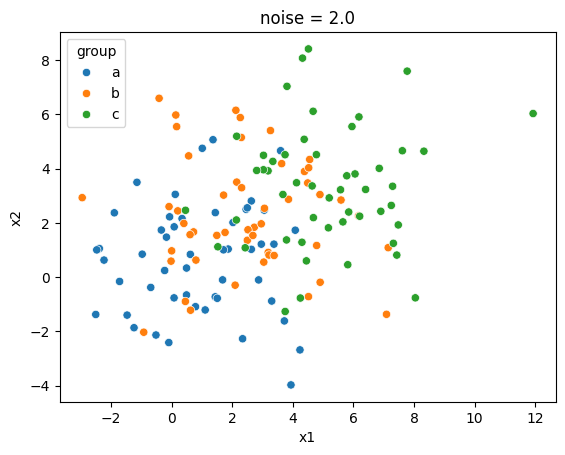

In [2]:
#Q1-2
import seaborn as sns
import matplotlib.pyplot as plt

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for i in range(5):
    sns.scatterplot(data=datasets[i], x="x1", y="x2", hue="group").set(title="noise = " + str(noises[i]))
    plt.show()

Q1-2 Explanation: As the noise goes up, the clusters get harder to tell apart. At 0.125 and 0.25, the three groups are tight and clearly separate. At 0.5 they start to spread out and touch. At 1.0 they overlap a lot, but we can still see that each color is centered in a different spot. At 2.0, all the points look like one big cluster, and all three groups mix into each other.

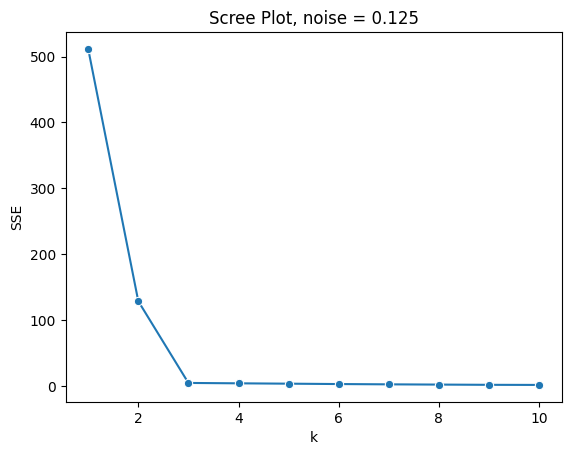

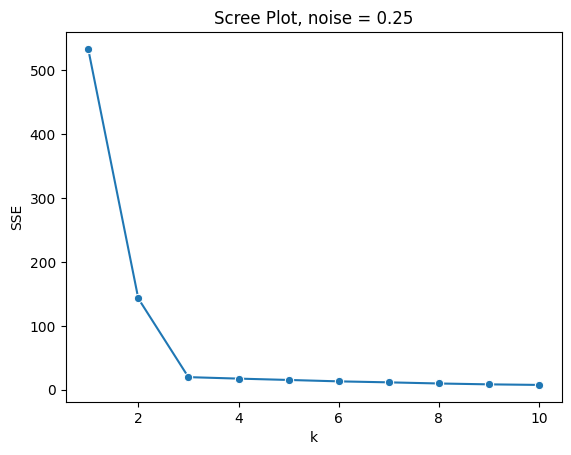

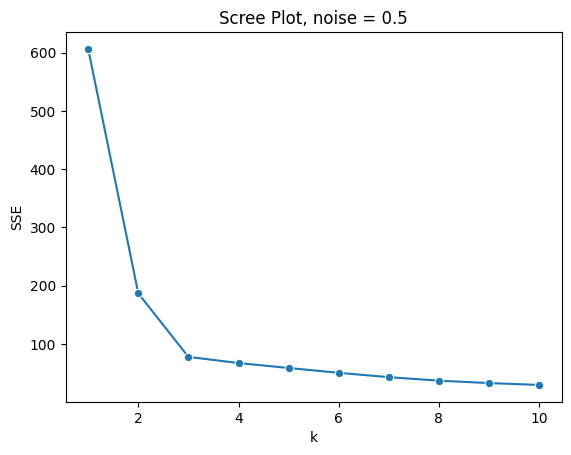

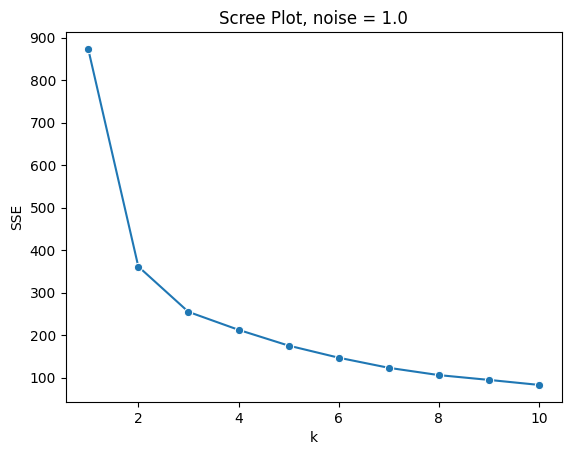

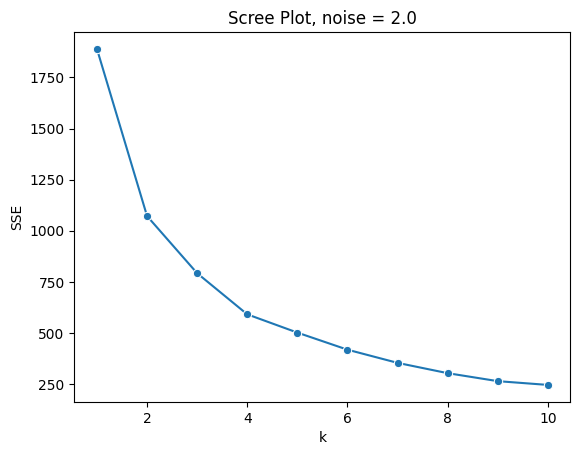

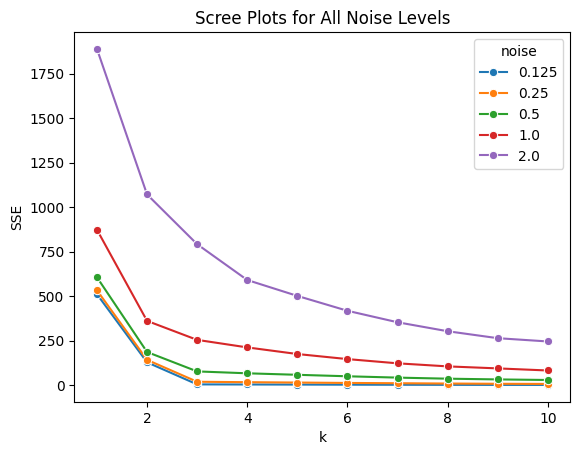

In [3]:
#Q1-3

from sklearn.cluster import KMeans

ks = np.arange(1, 11)
all_SSE = []

#individual plots
for i in range(5):
    X = datasets[i][["x1", "x2"]]
    SSE = []
    for k in ks:
        model = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
        SSE.append(model.inertia_)
    all_SSE.append(SSE)

    sns.lineplot(x=ks, y=SSE, marker="o").set(title="Scree Plot, noise = " + str(noises[i]), xlabel="k", ylabel="SSE")
    plt.show()

#plot with everything
for i in range(5):
    sns.lineplot(x=ks, y=all_SSE[i], marker="o", label=str(noises[i]))
plt.title("Scree Plots for All Noise Levels")
plt.xlabel("k")
plt.ylabel("SSE")
plt.legend(title="noise")
plt.show()

Q1-3 Explanation: As the noise goes up, the curve moves higher and the elbow gets weaker. At 0.125 and 0.25 there is a sharp elbow at k = 3, at 0.5 and 1.0 it gets less sharp, and at 2.0 the curve goes down with no clear elbow drop. With low noise it is easy to pick k = 3. At 1.0 it is harder because k = 2 and k = 3 both look reasonable, and at 2.0 we cannot confidently pick any k as there appears to be no elbow.

Q1-4 Explanation: The SSE generally goes down when we add a cluster, but the size of the drop tells us how much the new cluster improves the fit. In the low noise data there are 3 real groups, so going from k = 1 to 2 to 3 gives big drops in SSE. After k = 3, an extra cluster only splits a group that is already tight, so the SSE decreases much less. That switch from big drops to small drops is the elbow, and it suggests a good number of clusters. When the noise is high, the groups overlap so much that every new cluster helps a little, so there is no clear elbow.

In [4]:
#Q2-1
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020]
df = df.dropna()
df = df.drop(columns=["index", "Year"])
print(df.shape)
df.describe()

(148, 5)


,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.000000,148.000000,148.000000
mean,13153.747670,0.019619,0.061510,268.264494
std,68005.236120,0.015033,0.046207,430.434878
min,8.622460,0.000054,0.004896,0.580129
25%,204.877177,0.010413,0.031352,20.553464
50%,959.535443,0.015324,0.047402,81.506703
75%,5289.998320,0.024327,0.084681,326.267753
max,778397.200000,0.098470,0.303027,2520.398541


Q2-1 Explanation: After filtering to 2020 and dropping missing values there are 148 countries. All four spending variables are already numeric, so not much cleaning is needed. We drop the "index" and "Year" columns since they are not useful for clustering. We can also see that spending is skewed, as the United States spends much more than every other country.

     Spending (2020 USD)  Spending per Capita
min                  0.0                  0.0
max                  1.0                  1.0


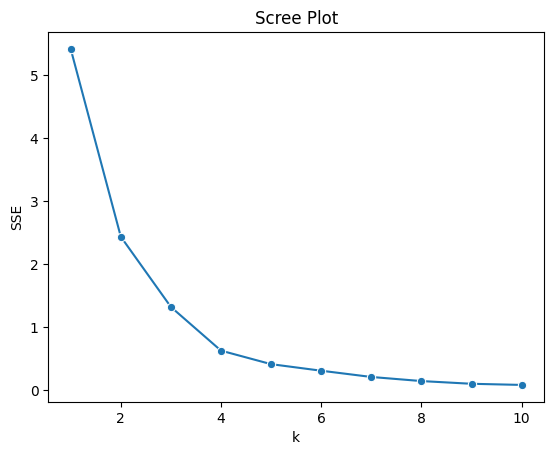

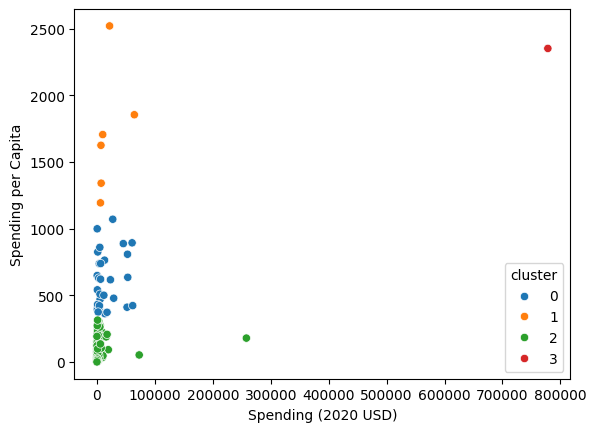

                       Country  Spending (2020 USD)  Percent of GDP  \
5540  United States of America             778397.2        0.037179   

      Percent of Government Spending  Spending per Capita  cluster  
5540                        0.081976          2351.631858        3  
0 ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Brunei', 'Canada', 'Cyprus', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Italy', 'Japan', 'Korea, South', 'Latvia', 'Lithuania', 'Luxembourg', 'Netherlands', 'New Zealand', 'Poland', 'Portugal', 'Russia', 'Slovakia', 'Spain', 'Sweden', 'Switzerland', 'Taiwan', 'United Kingdom']
1 ['Israel', 'Kuwait', 'Norway', 'Oman', 'Saudi Arabia', 'Singapore']
2 ['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon', 'Cape Verde', 'Central African Republic', 'Ch

Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Percent of GDP            ... Percent of Government Spending  \
                 count      mean  ...                            75%   
cluster                           ...                                  
0                 30.0  0.019397  ...                       0.048819   
1                  6.0  0.059781  ...                       0.164503   
2                111.0  0.017349  ...                       0.083508   
3                  1.0  0.037179  ...                       0.081976   

                  Spending per Capita                                        \
              max               count         mean         std          min   
cluster                                                                       
0        0.114776                30.0   607.478618  206.928757   362.467076   
1        0.225050                 6.0  1706.721916  466.375705  1193.598730   
2        0.303027               111.0    80.061470   83.501824     0.580129   
3        0.081976                 1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858  

[4 rows x 32 columns]

In [5]:
#Q2-2

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df[features]
X = (unscaled - unscaled.min()) / (unscaled.max() - unscaled.min())
print(X.agg(["min", "max"]))

#scree plot
ks = np.arange(1, 11)
SSE = []
for k in ks:
    model = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
    SSE.append(model.inertia_)
sns.lineplot(x=ks, y=SSE, marker="o").set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

#fit with k = 4
model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

sns.scatterplot(data=df, x="Spending (2020 USD)", y="Spending per Capita", hue="cluster", palette="tab10")
plt.show()

print(df[df["Country"] == "United States of America"])
for i in range(4):
    print(i, list(df[df["cluster"] == i]["Country"]))

df.groupby("cluster").describe()

Q2-2 Explanation: The scree plot has an elbow at k = 4, so we use 4 clusters. The United States is in a cluster by itself because its total spending is too large compared to other countries. The other clusters are mostly split by spending per capita. One small group is countries that spend a lot per person on the military. Another group is countries that spend a medium amount per person. The largest group is countries that spend little per person, and it also includes some countries that spend a lot such as China and India because their large populations make their per capita spending low.

     Percent of Government Spending  Percent of GDP
min                             0.0             0.0
max                             1.0             1.0


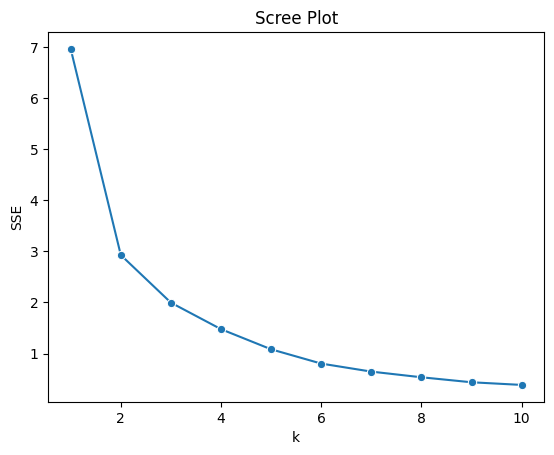

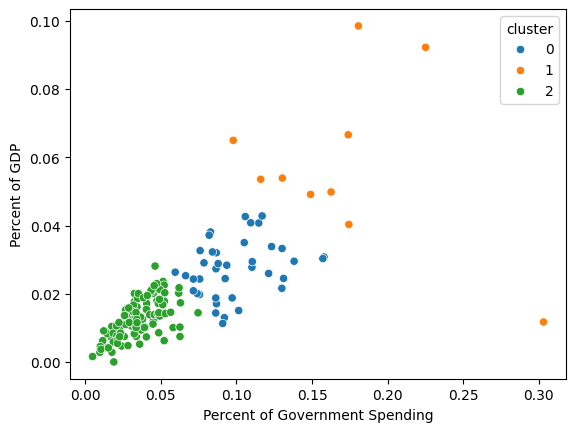

                       Country  Spending (2020 USD)  Percent of GDP  \
5540  United States of America             778397.2        0.037179   

      Percent of Government Spending  Spending per Capita  cluster  
5540                        0.081976          2351.631858        0  
0 ['Bahrain', 'Bangladesh', 'Botswana', 'Brunei', 'Burkina Faso', 'Burundi', 'Cambodia', 'Central African Republic', 'Chad', 'Chile', 'Colombia', 'Congo, Republic', 'Ecuador', 'Equatorial Guinea', 'Gabon', 'Guinea', 'India', 'Iran', 'Iraq', 'Korea, South', 'Lebanon', 'Mali', 'Mauritania', 'Morocco', 'Myanmar', 'Namibia', 'Niger', 'Russia', 'Singapore', 'South Sudan', 'Sri Lanka', 'Sudan', 'Taiwan', 'Togo', 'Tunisia', 'Turkey', 'Uganda', 'Ukraine', 'United States of America']
1 ['Algeria', 'Armenia', 'Azerbaijan', 'Belarus', 'Israel', 'Jordan', 'Kuwait', 'Oman', 'Pakistan', 'Saudi Arabia']
2 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosni

Spending (2020 USD)                                           \
                      count          mean            std         min   
cluster                                                                
0                      39.0  27387.150069  124489.244263   44.348098   
1                      10.0  12514.955945   19365.712246  633.960400   
2                      99.0   7611.174172   27958.296403    8.622460   

                                                               Percent of GDP  \
                 25%          50%           75%            max          count   
cluster                                                                         
0         310.624359  1157.372367   5786.787259  778397.200000           39.0   
1        2101.377796  6518.375529  10222.946276   64558.400000           10.0   
2         121.641398   567.650747   3910.107493  257973.429834           99.0   

                   ... Percent of Government Spending            \
             mean  ...                            75%       max   
cluster            ...                                            
0        0.027412  ...                       0.112633  0.157918   
1        0.058071  ...                       0.179081  0.303027   
2        0.012664  ...                       0.047402  0.074624   

        Spending per Capita                                                 \
                      count        mean         std        min         25%   
cluster                                                                      
0                      39.0  271.264618  484.849023   5.674383   24.603244   
1                      10.0  817.301890  904.866469  47.056944  204.615548   
2                      99.0  211.624304  278.496227   0.580129   16.487333   

                                               
                50%          75%          max  
cluster                                        
0        115.732975   209.705770  2351.631858  
1        221.050502  1517.266870  2520.398541  
2         72.164472   367.649743  1341.058851  

[3 rows x 32 columns]

In [6]:
#Q2-3

features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df[features]
X = (unscaled - unscaled.min()) / (unscaled.max() - unscaled.min())
print(X.agg(["min", "max"]))

#scree plot
SSE = []
for k in ks:
    model = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
    SSE.append(model.inertia_)
sns.lineplot(x=ks, y=SSE, marker="o").set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

#fit with k = 3
model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

sns.scatterplot(data=df, x="Percent of Government Spending", y="Percent of GDP", hue="cluster", palette="tab10")
plt.show()

print(df[df["Country"] == "United States of America"])
for i in range(3):
    print(i, list(df[df["cluster"] == i]["Country"]))

df.groupby("cluster").describe()

Q2-3 Explanation: The scree plot has an elbow around k = 3, so we use 3 clusters. The countries are split into low, medium and high groups based on how much of their economy and budget goes to the military. The low group is the largest and is mostly countries that do not prioritize military spending as they do not put a large share of their economy in the military. The medium group spends a moderate share of their economy on the military. The high group is a small set of countries that put a large share of their economy into the military. Compared to part 2, the United States is no longer in its own cluster and is in the medium group, since its spending is large in total but not as large when compared to the size of its economy.

     Spending (2020 USD)  Spending per Capita  Percent of Government Spending  \
min                  0.0                  0.0                             0.0   
max                  1.0                  1.0                             1.0   

     Percent of GDP  
min             0.0  
max             1.0  


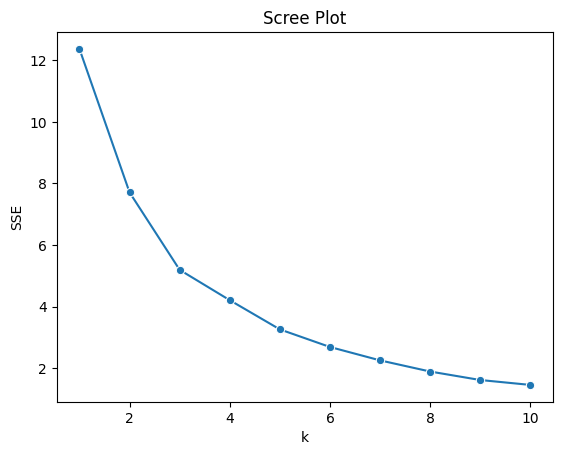

                       Country  Spending (2020 USD)  Percent of GDP  \
5540  United States of America             778397.2        0.037179   

      Percent of Government Spending  Spending per Capita  cluster  
5540                        0.081976          2351.631858        2  
0 ['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belgium', 'Belize', 'Benin', 'Bolivia', 'Bosnia and Herzegovina', 'Brazil', 'Bulgaria', 'Burundi', 'Cameroon', 'Canada', 'Cape Verde', 'Central African Republic', 'Chile', 'China', 'Congo, DR', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Estonia', 'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'Indonesia', 'Ireland', 'Italy', 'Jamaica', 'Japan', 'Kazakhstan', 'Kenya', 'Kosovo', 'Kyrgyz Republic', 'Latvia', 'Lesotho', 'Liberia'

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Percent of GDP            ... Percent of Government Spending  \
                 count      mean  ...                            75%   
cluster                           ...                                  
0                111.0  0.013419  ...                       0.050505   
1                 31.0  0.033492  ...                       0.134663   
2                  6.0  0.062634  ...                       0.164503   

                  Spending per Capita                                        \
              max               count         mean         std          min   
cluster                                                                       
0        0.092044               111.0   196.926833  267.788506     0.580129   
1        0.303027                31.0   212.689100  257.841988    18.297119   
2        0.225050                 6.0  1875.150751  489.800206  1193.598730   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          14.880549    67.083417   295.296094  1341.058851  
1          46.485917   135.459845   217.333791   998.966186  
2        1645.301864  1780.059564  2227.318999  2520.398541  

[3 rows x 32 columns]

In [7]:
#Q2-4

features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = df[features]
X = (unscaled - unscaled.min()) / (unscaled.max() - unscaled.min())
print(X.agg(["min", "max"]))

#scree plot
SSE = []
for k in ks:
    model = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
    SSE.append(model.inertia_)
sns.lineplot(x=ks, y=SSE, marker="o").set(title="Scree Plot", xlabel="k", ylabel="SSE")
plt.show()

#fit with k = 3
model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0).fit(X)
df["cluster"] = model.labels_

print(df[df["Country"] == "United States of America"])
for i in range(3):
    print(i, list(df[df["cluster"] == i]["Country"]))

df.groupby("cluster").describe()

Q2-4 Explanation: The scree plot has an elbow around k = 3, so we use 3 clusters. The smallest group is countries that spend a lot per person and put a large share of their economy into the military, although their total spending varies. The second group is countries that put a large share of their economy into the military but do not spend as much per person. The largest group is countries that generally put a smaller share of their economy into the military. The results look like a mix of parts 2 and 3. The groups are mostly split by share of the economy like in part 3, but the high per capita group from part 2 still appears. The United States is no longer in its own cluster and is now in the group with high per capita spending and high military spending shares.

Q2-5 Explanation: Yes, k means found some useful patterns. It showed that grouping countries by how much they spend gives very different results than grouping them by how much of their economy goes to the military. It also found a small group of countries with high spending per capita and high military spending shares, which would be hard to spot only from the raw data. However, the results can change depending on which variables we use and on the United States being an outlier, so the clusters are best used as a way to explore the data.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [8]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]